915


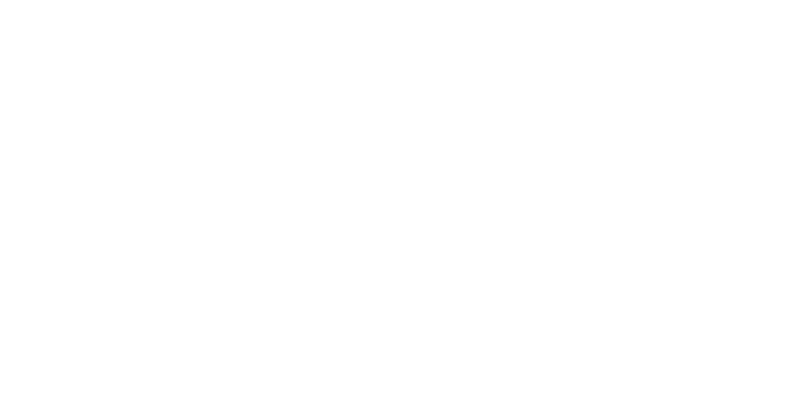

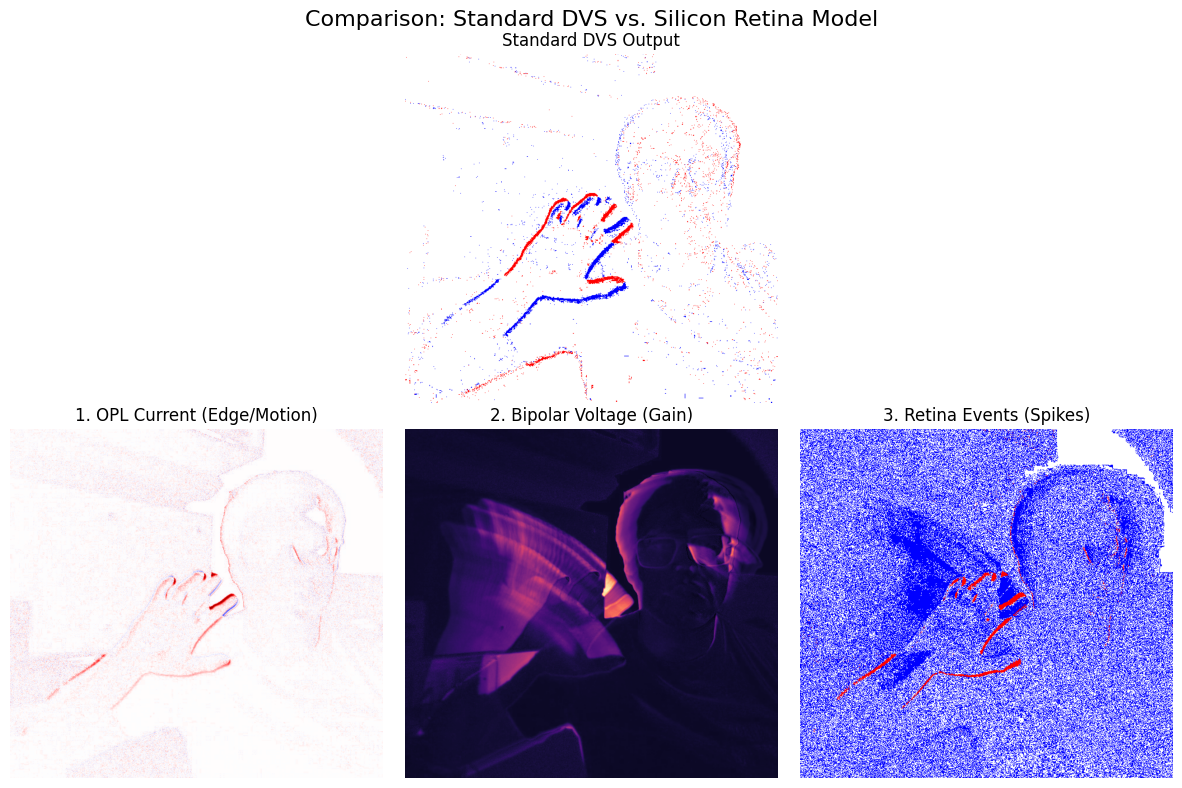

Saving raw images to visual_abstract_assets...
Done! Check the folder.
Saved LIF membrane states to visual_abstract_assets


In [1]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
import torch
from esim_torch import SiliconRetinaVerboseFloatCUDA, SiliconRetinaFloatCUDAOnline, SiliconRetinaConfig
from esim_torch.silicon_retina_cuda import BLUR_MODE, HPF_MODE, KERNEL_TYPE, Q_FEEDBACK_MODE


alpha1=0.5
alpha2=0.5
V_BIP_LPF_alpha=0.5
lambda_OPL=3.0
G_A_zero=0.5
lambda_A=0.5
p1=0.25
I_bias_on=0.01
I_bias_off=0.01
p2=1.0
p3=0.2
U_rest_on=-0.02
U_rest_off=0.02
U_th_on=0.05
U_th_off=0.05
U_reset_off=0.03
U_reset_on=0.03
HPF1_mode=0
HPF1_param=0.5
HPF2_mode=0
HPF2_param=0.5

blur1_mode=0
blur2_mode=0

kernel1_type=0
kernel2_type=0
kernel1_size=3
kernel2_size=3
kernel1_sigma=1.0
kernel2_sigma=1.0

q_feedback_mode=0

device = "cuda"

def visualize_events(events, width, height, t_end, t_start):
    # 1. Extract and Move to CPU
    x = events['x'].detach().cpu().numpy().astype(int)
    y = events['y'].detach().cpu().numpy().astype(int)
    t = events['t'].detach().cpu().numpy()
    p = events['p'].detach().cpu().numpy() # Assuming p is 0 (OFF) and 1 (ON) or -1/1

    # Filter by time (optional: usually you want the last N milliseconds of the batch)
    mask = np.logical_and(t_start <= t, t <= t_end)
    x, y, p = x[mask], y[mask], p[mask]

    # 2. Create Blank Canvas (White background often looks cleaner for papers)
    # Using White Background:
    img = np.full((height, width, 3), 255, dtype=np.uint8)

    # 3. Define Colors (BGR for OpenCV, RGB for Matplotlib)
    # Standard Convention: Red = ON (+), Blue = OFF (-)
    color_on = np.array([0, 0, 255])   # Red in BGR (if using cv2) / Blue in RGB
    color_off = np.array([255, 0, 0])  # Blue in BGR / Red in RGB

    # Note: Check your polarity encoding.
    # ESIM often uses 1 for ON, 0 or -1 for OFF.
    mask_pos = (p == 1)
    mask_neg = (p == 0) | (p == -1)

    # 4. Draw Events
    # We simply set the pixel color.
    # For a 'heatmap' style where density matters, you would need accumulation,
    # but for crisp feature visualization, direct setting is usually clearer.

    if len(x) > 0:
        # Set OFF events (Blue)
        img[y[mask_neg], x[mask_neg]] = color_off

        # Set ON events (Red) - drawn second to overlay if they overlap
        img[y[mask_pos], x[mask_pos]] = color_on

    return img

FPS = 90
dt = 1 / FPS

video_input = "high_speed_output.mp4"
cap = cv2.VideoCapture(video_input)

frames = []
frame_idx = 0

if not cap.isOpened():
    print("Couldn't open the file !")

else:
    while True:

        ret, frame = cap.read()

        if not ret:
            break

        frames.append(np.mean(frame, axis=-1))
        frame_idx += 1


import esim_torch

contrast_thresholds_neg = 0.2
contrast_thresholds_pos = 0.2

# create and reset simulator
event_simulator = esim_torch.ESIM(
            contrast_threshold_neg=contrast_thresholds_neg,
            contrast_threshold_pos=contrast_thresholds_pos,
            refractory_period_ns=0,
        )
event_simulator.reset()

# prepare the input
input_frames_dvs = np.array(frames.copy())
input_images = np.log(input_frames_dvs / 255.0 + 1e-4).astype(np.float32)
timestamps_ns = (np.arange(0, len(input_images)) * dt)

input_images = torch.from_numpy(input_images).to(device, non_blocking=True)
timestamps_ns = (1e9 * timestamps_ns).astype(np.int64)
timestamps_ns_t = torch.from_numpy(timestamps_ns).to(device, non_blocking=True)


# reset + simulate events
events = event_simulator.forward(input_images, timestamps_ns_t)
x, y, t, p = events["x"], events["y"], events["t"], events["p"]  # GPU tensors


H, W = input_frames_dvs.shape[1], input_frames_dvs.shape[2]
print(len(input_images))

start_frame = 900
end_frame = 902
ms_period = round((end_frame - start_frame) / FPS * 1e3, 1)

# Generate the image
event_viz = visualize_events(events, width=W, height=H, t_start = int(start_frame / FPS * 1e9), t_end= int(end_frame / FPS * 1e9) ) # 30ms window

# Display
plt.figure(figsize=(10, 5))

#plt.title(f"DVS Events (Accumulated {ms_period} ms), starting_at {round(start_frame / FPS *1e3, 1)}, ending_at {round(end_frame / FPS *1e3, 1)}")
plt.savefig("events_visualized.jpg")
plt.axis('off')
plt.show()

cv2.imwrite("events_visualized.jpg", cv2.cvtColor(event_viz, cv2.COLOR_BGR2RGB))


def visualize_retina_frames(pos_tensor, neg_tensor, start_idx, end_idx, height, width):
    """
    Visualizes dense retina event frames (T, H, W) as a single Red/Blue image.
    Matches the style of the DVS visualization.
    """
    # 1. Create Blank White Canvas
    img = np.full((height, width, 3), 255, dtype=np.uint8)

    # 2. Extract window and collapse time
    # We take the logical OR across the time dimension to see if an event happened
    # in this window. (Summing is also an option if you want density).

    # Slice the tensor [Time, Height, Width]
    # Ensure we are on CPU and numpy
    p_chunk = pos_tensor[start_idx:end_idx].cpu().numpy()
    n_chunk = neg_tensor[start_idx:end_idx].cpu().numpy()

    # Collapse: if ANY frame in the window has a spike, mark it.
    pos_mask = np.any(p_chunk > 0, axis=0) # Shape: (H, W)
    neg_mask = np.any(n_chunk > 0, axis=0)

    # 3. Define Colors (BGR for OpenCV consistency with your previous code)
    color_on = np.array([0, 0, 255])   # Red
    color_off = np.array([255, 0, 0])  # Blue

    # 4. Draw
    # Draw Negative (Blue) first
    img[neg_mask] = color_off
    # Draw Positive (Red) on top
    img[pos_mask] = color_on

    return img

def visualize_heatmap(tensor_data, frame_idx, cmap_name='seismic', normalize_sym=True):
    """
    Visualizes an analog intermediate state (OPL, Voltage) as a heatmap.
    """
    # Extract specific frame
    data = tensor_data[frame_idx].cpu().numpy()

    # Normalize
    if normalize_sym:
        # For OPL (Difference of Gaussians), 0 should be gray.
        # We find the max absolute value to center the colormap at 0.
        max_val = np.max(np.abs(data)) + 1e-5
        norm_data = data / max_val # Now between -1 and 1
        # Shift to 0-1 for matplotlib colormap
        norm_data = (norm_data + 1) / 2.0
    else:
        # For Gain/Voltage (0 to Max)
        min_val = np.min(data)
        max_val = np.max(data) + 1e-5
        norm_data = (data - min_val) / (max_val - min_val)

    # Apply Colormap
    cmap = plt.get_cmap(cmap_name)
    colored_img = cmap(norm_data) # Returns RGBA float 0-1

    # Convert to RGB uint8 0-255
    img_uint8 = (colored_img[:, :, :3] * 255).astype(np.uint8)
    return img_uint8


H, W = frames[0].shape
T = len(frames)

cfg = SiliconRetinaConfig(H = H,
                          W = W,
                          alpha1=alpha1,
                          alpha2=alpha2,
                          V_BIP_LPF_alpha=V_BIP_LPF_alpha,
                          lambda_OPL=lambda_OPL,
                          G_A_zero=G_A_zero,
                          lambda_A=lambda_A,
                          p1=p1,
                          I_bias_on=I_bias_on,
                          I_bias_off=I_bias_off,
                          p2=p2,
                          p3=p3,
                          U_rest_on=U_rest_on,
                          U_rest_off=U_rest_off,
                          U_th_on=U_th_on,
                          U_th_off=U_th_off,
                          U_reset_on=U_reset_on,
                          U_reset_off=U_reset_off,

                          HPF1_mode=HPF1_mode,
                          HPF1_param=HPF1_param,

                          HPF2_mode=HPF2_mode,
                          HPF2_param=HPF2_param,

                          blur1_mode=blur1_mode,
                          blur2_mode=blur2_mode,

                          kernel1_type=kernel1_type,
                          kernel2_type=kernel2_type,
                          kernel1_size=kernel1_size,
                          kernel2_size=kernel2_size,
                          kernel1_sigma=kernel1_sigma,
                          kernel2_sigma=kernel2_sigma,

                          q_feedback_mode=q_feedback_mode)

model = SiliconRetinaFloatCUDAOnline(silicon_retina_config=cfg)

positive, negative = [], []
opl_storage = []
bip_storage = []
V_LIF_on = []
V_LIF_off = []

model.reset()
for t in range(1, T+1, 1):

    input = (frames[t-1][None] / 255.).astype(np.float32)
    input = torch.Tensor(input).to(device)
    p, n = model(input, t)
    positive.append((p.clone()[0]))
    negative.append((n.clone()[0]))

    if start_frame <= t <= end_frame:
        # Clone is important because model state is overwritten
        opl_storage.append(model.I_OPL[t%2].clone())
        bip_storage.append(model.V_BIP[t%2].clone())
        V_LIF_on.append(model.V_LIF_on[t%2].clone())
        V_LIF_off.append(model.V_LIF_off[t%2].clone())

positive = torch.stack(positive, dim=0)
negative = torch.stack(negative, dim=0)

# Stack intermediates (they will only have length = end_frame - start_frame)
opl_stack = torch.stack(opl_storage, dim=0)
bip_stack = torch.stack(bip_storage, dim=0)

# Stack the new LIF states
v_lif_on_stack = torch.stack(V_LIF_on, dim=0)
v_lif_off_stack = torch.stack(V_LIF_off, dim=0)


# --- 1. Prepare Data ---
# DVS Image (Top Row)
dvs_img_bgr = visualize_events(events, width=W, height=H,
                               t_start=int(start_frame / FPS * 1e9),
                               t_end=int(end_frame / FPS * 1e9))
dvs_img_rgb = cv2.cvtColor(dvs_img_bgr, cv2.COLOR_BGR2RGB)

# Retina Event Image (Bottom Row - Output)
retina_evt_bgr = visualize_retina_frames(positive, negative, start_frame, end_frame, H, W)
retina_evt_rgb = cv2.cvtColor(retina_evt_bgr, cv2.COLOR_BGR2RGB)

# Intermediate: OPL (Center-Surround)
# Use the middle frame of the window for the snapshot
mid_idx = (end_frame - start_frame) // 2
opl_img_rgb = visualize_heatmap(opl_stack, mid_idx, cmap_name='seismic', normalize_sym=True)

# Intermediate: Bipolar Voltage (Contrast Control)
bip_img_rgb = visualize_heatmap(bip_stack, mid_idx, cmap_name='magma', normalize_sym=False)


# --- 2. Plotting ---
fig = plt.figure(figsize=(12, 8))
plt.suptitle("Comparison: Standard DVS vs. Silicon Retina Model", fontsize=16)

# == ROW 1: Standard DVS ==
ax1 = plt.subplot(2, 3, 2) # Center it on the top row
ax1.imshow(dvs_img_rgb)
ax1.set_title("Standard DVS Output")
ax1.axis('off')

# == ROW 2: Silicon Retina Pipeline ==
# 2.1 OPL (Analog)
ax2 = plt.subplot(2, 3, 4)
ax2.imshow(opl_img_rgb)
ax2.set_title("1. OPL Current (Edge/Motion)")
ax2.axis('off')

# 2.2 Bipolar (Analog)
ax3 = plt.subplot(2, 3, 5)
ax3.imshow(bip_img_rgb)
ax3.set_title("2. Bipolar Voltage (Gain)")
ax3.axis('off')

# 2.3 Retina Output (Events)
ax4 = plt.subplot(2, 3, 6)
ax4.imshow(retina_evt_rgb)
ax4.set_title("3. Retina Events (Spikes)")
ax4.axis('off')

plt.tight_layout()
plt.savefig("visual_abstract.jpg", dpi=300)
plt.show()

import cv2
import os

# Create a directory for outputs to keep things organized
output_dir = "visual_abstract_assets"
os.makedirs(output_dir, exist_ok=True)

print(f"Saving raw images to {output_dir}...")

# --- 1. Save DVS Output ---
# We already have 'dvs_img_bgr' from the previous step, so we can save it directly.
cv2.imwrite(f"{output_dir}/1_standard_dvs.png", dvs_img_bgr)


# --- 2. Save OPL (Outer Plexiform Layer) ---
# 'opl_img_rgb' was created for matplotlib (RGB).
# We must convert it back to BGR for OpenCV saving.
opl_img_bgr = cv2.cvtColor(opl_img_rgb, cv2.COLOR_RGB2BGR)
cv2.imwrite(f"{output_dir}/2_retina_stage1_opl.png", opl_img_bgr)


# --- 3. Save Bipolar/Gain Layer ---
# Same here: Convert RGB -> BGR
bip_img_bgr = cv2.cvtColor(bip_img_rgb, cv2.COLOR_RGB2BGR)
cv2.imwrite(f"{output_dir}/3_retina_stage2_bipolar.png", bip_img_bgr)


# --- 4. Save Retina Events Output ---
# We already have 'retina_evt_bgr' from the previous step.
cv2.imwrite(f"{output_dir}/4_retina_stage3_events.png", retina_evt_bgr)

print("Done! Check the folder.")

# Select the middle frame of the captured window for the snapshot
mid_idx = (end_frame - start_frame) // 2

# --- Visualize LIF ON Membrane ---
# normalize_sym=False because voltage is usually 0 to Threshold (not negative)
lif_on_img_rgb = visualize_heatmap(v_lif_on_stack, mid_idx, cmap_name='inferno', normalize_sym=False)
lif_on_img_bgr = cv2.cvtColor(lif_on_img_rgb, cv2.COLOR_RGB2BGR)

# --- Visualize LIF OFF Membrane ---
lif_off_img_rgb = visualize_heatmap(v_lif_off_stack, mid_idx, cmap_name='inferno', normalize_sym=False)
lif_off_img_bgr = cv2.cvtColor(lif_off_img_rgb, cv2.COLOR_RGB2BGR)

# --- Save to Disk ---
output_dir = "visual_abstract_assets"
os.makedirs(output_dir, exist_ok=True)

cv2.imwrite(f"{output_dir}/5_retina_stage3_lif_on.png", lif_on_img_bgr)
cv2.imwrite(f"{output_dir}/6_retina_stage3_lif_off.png", lif_off_img_bgr)

print(f"Saved LIF membrane states to {output_dir}")